# RutaPro · Notebook 03: Evaluación final y selección del modelo

**Fase 5 del trabajo.** Los hiperparámetros quedaron fijados en el notebook 02 usando solo validación. Aquí:

1. Se **reentrena** cada modelo con entrenamiento + validación y se evalúa **una sola vez** en prueba.
2. Se reportan Precision, Recall, Hit Rate y NDCG para **K = 5 y K = 10**, y la curva completa de K = 1 a 20.
3. Se verifica si las diferencias frente al baseline son **estadísticamente significativas**.
4. Se repite la comparación con el **corte temporal global** (prueba de robustez).
5. Se analizan métricas **más allá de la precisión** (cobertura, novedad, diversidad, respeto del idioma) y resultados **por tipo de estudiante**.
6. Se evalúa la estrategia de **cold start**.
7. Se **selecciona** el modelo considerando desempeño, costo y utilidad, y se exporta para la aplicación.

**Protocolo común (igual para todos los modelos):** mismos estudiantes elegibles, misma definición de relevancia (inscripción), mismos K y exclusión de los cursos en los que el estudiante ya se inscribió antes del periodo de prueba.

In [1]:
import os, sys, subprocess
from google.colab import drive

NECESITA_LIGHTFM = True

# 1) Conectar el Drive y entrar a la carpeta del proyecto
drive.mount('/content/drive')
PROY = "/content/drive/MyDrive/RutaPro"
os.chdir(PROY + "/02_Notebooks")
print("Carpeta actual:", os.getcwd())

# 2) Comprobar que están los archivos imprescindibles
faltan = [f for f in ["rutapro_rec.py", "rutapro_sim.py", "rutapro_extra.py", "rutapro_mooc.py",
                      "resultados/hiperparametros.json", "../01_Datos/cursos.csv",
                      "../01_Datos/pares_usuario_curso.csv"] if not os.path.exists(f)]
print("Archivos que faltan:", faltan if faltan else "ninguno, todo en su sitio")

# 3) LightFM: usa la copia compilada en el Drive; si no existe, la compila (≈ 2 min) y la guarda
def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-1500:], r.stderr[-1500:])
        raise RuntimeError("Falló: " + cmd[:70])

if NECESITA_LIGHTFM:
    LF = PROY + "/lightfm_src"
    if not os.path.exists(LF + "/lightfm"):
        print("Compilando LightFM, un momento...")
        sh("pip install -q cython")
        sh("rm -rf /content/lightfm_src && git clone -q --depth 1 https://github.com/lyst/lightfm.git /content/lightfm_src")
        p = "/content/lightfm_src/setup.py"
        s = open(p).read()
        s = s.replace("compiler_directives={'language_level' : \"3\"}",
                      "compiler_directives={'language_level': \"3\", 'legacy_implicit_noexcept': True}").replace("-march=native", "-O2")
        open(p, "w").write(s)
        sh("cd /content/lightfm_src && python setup.py cythonize -q && python setup.py build_ext --inplace -q")
        sh("rm -rf '" + LF + "' && cp -r /content/lightfm_src '" + LF + "'")
    sys.path.insert(0, LF)
    import lightfm
    print("LightFM", lightfm.__version__)

Mounted at /content/drive
Carpeta actual: /content/drive/MyDrive/RutaPro/02_Notebooks
Archivos que faltan: ninguno, todo en su sitio
LightFM 1.17


In [ ]:
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import stats
warnings.filterwarnings("ignore")
import rutapro_rec as rr

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#9a9890"
TXT, TXT2 = "#0b0b0b", "#52514e"
mpl.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d4d3cd", "axes.labelcolor": TXT2, "xtick.color": TXT2, "ytick.color": TXT2,
    "text.color": TXT, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ebeae6",
    "axes.axisbelow": True, "font.size": 10, "figure.dpi": 110,
})
BASE = rr.ruta_base()
FIG = BASE / "04_Informe" / "figuras"; RES = BASE / "02_Notebooks" / "resultados"
def guardar(fig, n): fig.savefig(FIG / f"{n}.png", dpi=160, bbox_inches="tight")

cursos, usuarios, pares = rr.cargar_datos()
H = json.loads((RES / "hiperparametros.json").read_text())
prueba = rr.construir_particion(cursos, usuarios, pares, etapa="prueba", esquema="usuario")
eleg = prueba.usuarios_elegibles()
print(f"Entrenamiento (train + valid): {len(prueba.train)} pares, {prueba.train.positivo.sum()} positivos")
print(f"Prueba: {len(prueba.evaluar)} inscripciones de {len(eleg)} estudiantes elegibles")
print(json.dumps({k: v for k, v in H.items() if k != 'criterio'}, ensure_ascii=False))

Entrenamiento (train + valid): 1445 pares, 792 positivos
Prueba: 199 inscripciones de 133 estudiantes elegibles
{"Contenido (TF-IDF)": {"ngram": [1, 1], "alpha_perfil": 0.9, "usar_vistas": false}, "KNN usuario": {"k": 20, "variante": "usuario", "usar_vistas": false}, "KNN ítem": {"k": 5, "variante": "item", "usar_vistas": true}, "LightFM híbrido": {"no_components": 64, "loss": "warp", "epochs": 200}}


### Modelos evaluados
Además de los cinco modelos del notebook 02 se evalúa **LightFM + reglas**: el mismo LightFM, pero aplicando al Top-N las reglas de negocio definidas para el *cold start* (no mostrar cursos en inglés a quien solo lee español y no saltar más de un nivel). Es la versión que se usaría en producción si el modelo puro recomendara cursos inadecuados.

LightFM es estocástico: sus métricas se reportan como **media de 5 semillas**. Para las pruebas estadísticas y los análisis por estudiante se usa la semilla 42, que es la que se exporta a la aplicación.

In [ ]:
perfil_de = usuarios.set_index("user_id").to_dict("index")

class ConReglas:
    # Aplica las reglas de idioma y nivel sobre los puntajes de otro modelo
    def __init__(self, base, nombre): self.base, self.nombre = base, nombre
    def puntajes(self, u): return rr.aplicar_reglas(self.base.puntajes(u), cursos, perfil_de[u])

def construir(seed=42):
    c, ku, ki, lf = H["Contenido (TF-IDF)"], H["KNN usuario"], H["KNN ítem"], H["LightFM híbrido"]
    return {
        "Popularidad": rr.Popularidad(),
        "Contenido (TF-IDF)": rr.ContenidoTFIDF(ngram=tuple(c["ngram"]), alpha_perfil=c["alpha_perfil"], usar_vistas=c["usar_vistas"]),
        "KNN usuario": rr.KNNColaborativo(k=ku["k"], variante="usuario", usar_vistas=ku["usar_vistas"]),
        "KNN ítem": rr.KNNColaborativo(k=ki["k"], variante="item", usar_vistas=ki["usar_vistas"]),
        "LightFM híbrido": rr.LightFMHibrido(**lf, seed=seed),
    }

modelos, tiempos = construir(), {}
for n, m in modelos.items():
    t0 = time.perf_counter(); m.fit(prueba); tiempos[n] = time.perf_counter() - t0
modelos["LightFM + reglas"] = ConReglas(modelos["LightFM híbrido"], "LightFM + reglas")
tiempos["LightFM + reglas"] = tiempos["LightFM híbrido"]

res, det, recs = {}, {}, {}
for n, m in modelos.items():
    t0 = time.perf_counter()
    res[n], det[n], recs[n] = rr.evaluar(m, prueba, ks=range(1, 21), devolver_detalle=True)
    tiempos[n + " · inferencia"] = (time.perf_counter() - t0) / len(eleg) * 1000

# LightFM: media y desviación de 5 semillas
semillas = {}
for s in [42, 43, 44, 45, 46]:
    m = rr.LightFMHibrido(**H["LightFM híbrido"], seed=s).fit(prueba)
    semillas[s] = {"puro": rr.evaluar(m, prueba), "reglas": rr.evaluar(ConReglas(m, ""), prueba)}
print("Listo.")

Listo.


## 1. Resultados en prueba con K = 5 y K = 10

In [ ]:
filas = []
for K in (5, 10):
    for n in modelos:
        r = res[n].loc[K]
        fila = {"K": K, "modelo": n, **r[["precision", "recall", "hit_rate", "ndcg", "cobertura"]]}
        if n.startswith("LightFM"):
            key = "puro" if n == "LightFM híbrido" else "reglas"
            v = pd.DataFrame([semillas[s][key].loc[K] for s in semillas])
            for met in ["precision", "recall", "hit_rate", "ndcg", "cobertura"]:
                fila[met] = v[met].mean()
            fila["ndcg_sd"] = v["ndcg"].std()
        filas.append(fila)
tabla_test = pd.DataFrame(filas).set_index(["K", "modelo"])
tabla_test.to_csv(RES / "metricas_prueba.csv")
tabla_test.round(3)

precision  recall  hit_rate   ndcg  cobertura  ndcg_sd
K  modelo                                                                    
5  Popularidad             0.051   0.174     0.233  0.102      0.103      NaN
   Contenido (TF-IDF)      0.042   0.148     0.203  0.088      0.617      NaN
   KNN usuario             0.041   0.140     0.203  0.098      0.579      NaN
   KNN ítem                0.044   0.155     0.203  0.109      0.944      NaN
   LightFM híbrido         0.065   0.241     0.313  0.153      0.643    0.009
   LightFM + reglas        0.065   0.242     0.310  0.154      0.650    0.010
10 Popularidad             0.039   0.264     0.346  0.134      0.159      NaN
   Contenido (TF-IDF)      0.037   0.254     0.346  0.126      0.879      NaN
   KNN usuario             0.034   0.229     0.316  0.129      0.729      NaN
   KNN ítem                0.032   0.210     0.286  0.130      1.000      NaN
   LightFM híbrido         0.052   0.369     0.462  0.199      0.783    0.004
   LightFM + reglas        0.050   0.354     0.438  0.195      0.789    0.004

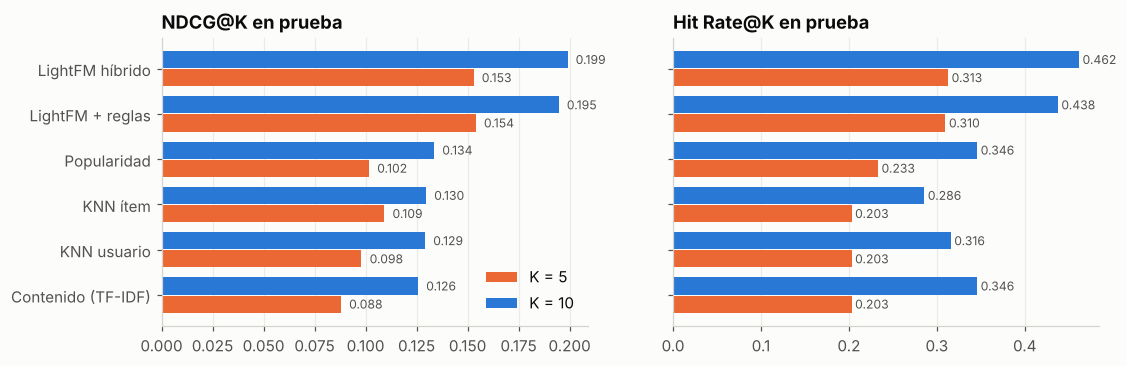

In [ ]:
orden = tabla_test.loc[10].sort_values("ndcg").index
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, met, tit in zip(axes, ["ndcg", "hit_rate"], ["NDCG", "Hit Rate"]):
    for j, (K, c) in enumerate([(5, NARANJA), (10, AZUL)]):
        v = tabla_test.loc[K].loc[orden, met]
        y = np.arange(len(orden)) + (0.2 if K == 10 else -0.2)
        ax.barh(y, v, height=0.38, color=c, label=f"K = {K}")
        for yi, vi in zip(y, v): ax.text(vi + 0.004, yi, f"{vi:.3f}", va="center", fontsize=8, color=TXT2)
    ax.set_title(f"{tit}@K en prueba"); ax.grid(axis="y", visible=False)
axes[0].set_yticks(np.arange(len(orden)), orden); axes[0].legend(frameon=False, loc="lower right")
guardar(fig, "16_resultados_prueba"); plt.show()

**Interpretación.** En prueba, **LightFM** es el único modelo que se separa claramente del resto.
- **LightFM puro:** NDCG@10 de 0.199 ± 0.004 entre semillas, frente a 0.134 de la popularidad (+49 %). Su Hit Rate@10 es 0.46, es decir, para casi la mitad de los estudiantes al menos uno de los 10 cursos recomendados fue un curso en el que efectivamente se inscribió después.
- **LightFM + reglas:** obtiene prácticamente lo mismo (0.195; la diferencia está dentro de la variación entre semillas).
- **Popularidad, KNN y contenido:** quedan muy juntos (NDCG@10 entre 0.126 y 0.134).

El contenido TF-IDF, que en validación superaba a la popularidad, en prueba queda ligeramente por debajo. Era una ventaja pequeña y no se sostuvo en datos nuevos. La Precision@K es baja en todos los modelos porque cada estudiante tiene en promedio 1.5 inscripciones en prueba: con K = 10 el máximo alcanzable ronda 0.15.

## 2. Sensibilidad al valor de K

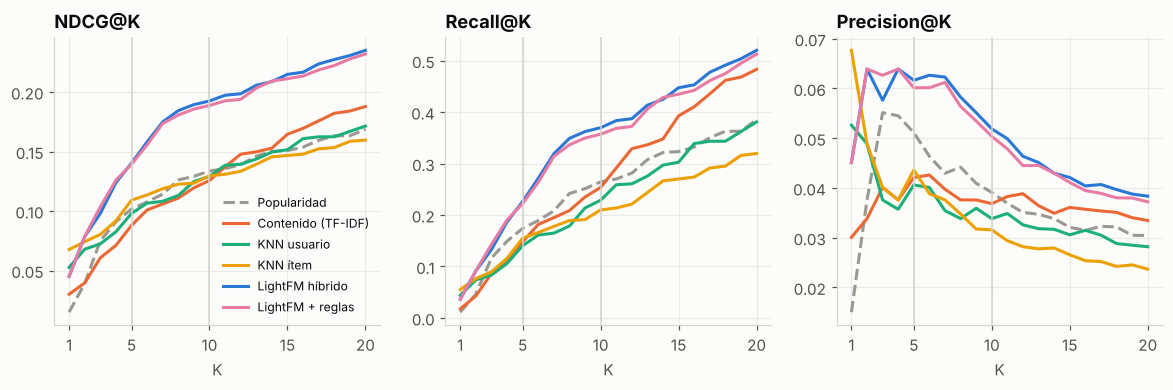

,precision,recall,hit_rate,ndcg
K,,,,
1,0.045,0.036,0.045,0.045
3,0.058,0.133,0.173,0.098
5,0.062,0.226,0.301,0.140
10,0.052,0.370,0.474,0.192
15,0.042,0.447,0.534,0.215
20,0.038,0.520,0.632,0.235


In [ ]:
nombres = ["Popularidad", "Contenido (TF-IDF)", "KNN usuario", "KNN ítem", "LightFM híbrido", "LightFM + reglas"]
cols = dict(zip(nombres, [GRIS, NARANJA, AQUA, AMARILLO, AZUL, MAGENTA]))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, met, tit in zip(axes, ["ndcg", "recall", "precision"], ["NDCG@K", "Recall@K", "Precision@K"]):
    for n in nombres:
        ax.plot(res[n].index, res[n][met], lw=2, color=cols[n], label=n, ls="--" if n == "Popularidad" else "-")
    for K in (5, 10): ax.axvline(K, color="#d4d3cd", lw=1)
    ax.set_title(tit); ax.set_xlabel("K"); ax.set_xticks([1, 5, 10, 15, 20])
axes[0].legend(frameon=False, fontsize=8)
guardar(fig, "17_sensibilidad_k"); plt.show()
res["LightFM híbrido"].loc[[1, 3, 5, 10, 15, 20], ["precision", "recall", "hit_rate", "ndcg"]].round(3)

**Interpretación.** *(Curvas con la semilla 42; la tabla de la sección 1 promedia 5 semillas.)*
- **NDCG y Recall:** crecen con K en todos los modelos, porque una lista más larga tiene más oportunidades de acertar. LightFM se mantiene por encima de los demás para cualquier K mayor o igual a 3, así que la conclusión no depende del K elegido.
- **Precision:** LightFM alcanza su máximo entre K = 2 y K = 7 (≈ 0.06) y luego baja, porque se agregan cursos con menos probabilidad de acierto.
- **Elección de K = 10 para la aplicación:** al pasar de K = 5 a K = 10, el Hit Rate de LightFM sube de 0.30 a 0.46 (+16 puntos) con poca pérdida de precisión. Además, 10 cursos es una lista que un estudiante puede revisar en una sola pantalla. Por encima de 10, cada curso adicional aporta menos (de K = 10 a K = 20 el Hit Rate sube 16 puntos, pero con el doble de cursos que revisar).

En la app se muestran 10 recomendaciones y se destacan las 5 primeras.

## 3. ¿Las diferencias son significativas?

Con 133 estudiantes, una diferencia de NDCG puede deberse al azar. Para cada modelo se compara su NDCG@10 **por estudiante** con el de la popularidad (datos pareados):
- **Prueba de Wilcoxon de rangos con signo** (no paramétrica, adecuada porque el NDCG por estudiante no es normal: la mayoría vale 0).
- **Intervalo de confianza bootstrap al 95 %** de la diferencia media (5 000 remuestreos de estudiantes).
- Corrección de **Holm** por comparaciones múltiples.

In [ ]:
rng = np.random.default_rng(42)
base = det["Popularidad"].query("K == 10").set_index("user_id")["ndcg"]
filas = []
for n in nombres[1:]:
    d = det[n].query("K == 10").set_index("user_id")["ndcg"].reindex(base.index) - base
    boot = [rng.choice(d.values, len(d)).mean() for _ in range(5000)]
    p = stats.wilcoxon(d[d != 0]).pvalue if (d != 0).sum() > 0 else 1.0
    filas.append({"modelo": n, "diferencia media NDCG@10": d.mean(), "IC95 inf": np.percentile(boot, 2.5),
                  "IC95 sup": np.percentile(boot, 97.5), "mejora (estudiantes)": (d > 0).sum(),
                  "empeora (estudiantes)": (d < 0).sum(), "p (Wilcoxon)": p})
sig = pd.DataFrame(filas).set_index("modelo")
# Corrección de Holm: p ordenados de menor a mayor, multiplicados por (m - i) y forzados a ser no decrecientes
orden_p = sig["p (Wilcoxon)"].sort_values()
m_ = len(orden_p)
holm = pd.Series([min(1, p * (m_ - i)) for i, p in enumerate(orden_p.values)], index=orden_p.index).cummax()
sig["p ajustado (Holm)"] = holm.reindex(sig.index)
sig["¿significativo al 5 %?"] = np.where(sig["p ajustado (Holm)"] < 0.05, "sí", "no")
sig.round(4)

,diferencia media NDCG@10,IC95 inf,IC95 sup,mejora (estudiantes),empeora (estudiantes),p (Wilcoxon),p ajustado (Holm),¿significativo al 5 %?
modelo,,,,,,,,
Contenido (TF-IDF),-0.0079,-0.0570,0.0411,35,37,0.7490,1.0000,no
KNN usuario,-0.0044,-0.0428,0.0345,27,28,0.6998,1.0000,no
KNN ítem,-0.0040,-0.0486,0.0413,29,32,0.6560,1.0000,no
LightFM híbrido,0.0589,0.0159,0.1000,48,23,0.0027,0.0134,sí
LightFM + reglas,0.0551,0.0122,0.1002,47,24,0.0065,0.0259,sí


In [ ]:
# Comparación directa entre los dos mejores candidatos
a = det["LightFM híbrido"].query("K == 10").set_index("user_id")["ndcg"]
b = det["Contenido (TF-IDF)"].query("K == 10").set_index("user_id")["ndcg"].reindex(a.index)
d = a - b
boot = [rng.choice(d.values, len(d)).mean() for _ in range(5000)]
print(f"LightFM − Contenido: diferencia media NDCG@10 = {d.mean():.3f} "
      f"(IC95 {np.percentile(boot, 2.5):.3f} a {np.percentile(boot, 97.5):.3f}), p Wilcoxon = {stats.wilcoxon(d[d != 0]).pvalue:.4f}")

LightFM − Contenido: diferencia media NDCG@10 = 0.067 (IC95 0.022 a 0.114), p Wilcoxon = 0.0090


**Interpretación.**
- **LightFM frente a la popularidad:** es el único modelo con una mejora **estadísticamente significativa** (p = 0.013 con corrección de Holm). El intervalo de confianza al 95 % de la mejora en NDCG@10 va de +0.016 a +0.100 y no incluye el cero. LightFM mejora a 48 estudiantes y empeora a 23. LightFM + reglas también es significativo (p = 0.026).
- **Contenido, KNN usuario y KNN ítem:** no se distinguen de la popularidad (p > 0.6; los intervalos cruzan el cero).
- **LightFM frente a contenido:** LightFM es significativamente mejor (diferencia +0.067; IC95 de 0.022 a 0.114).

Con 133 estudiantes no se puede afirmar que contenido o KNN sean peores ni mejores que recomendar lo más popular.

## 4. Prueba de robustez: corte temporal global

Se repite la evaluación con el esquema A del notebook 01 (una misma fecha de corte para todos). Aquí **no hay fuga entre usuarios**: nada posterior al corte se usa para entrenar. La desventaja es que hay muchos menos estudiantes evaluables, así que las cifras son más ruidosas. Lo importante es si el **orden** de los modelos se mantiene.

In [ ]:
glob = rr.construir_particion(cursos, usuarios, pares, etapa="prueba", esquema="global")
print(f"Estudiantes elegibles con corte global: {len(glob.usuarios_elegibles())}")
mods_g = construir()
res_g = {n: rr.evaluar(m.fit(glob), glob) for n, m in mods_g.items()}
res_g["LightFM + reglas"] = rr.evaluar(ConReglas(mods_g["LightFM híbrido"], ""), glob)
lfm_g, lfmr_g = [], []
for s_ in [42, 43, 44, 45, 46]:
    m_g = rr.LightFMHibrido(**H["LightFM híbrido"], seed=s_).fit(glob)
    lfm_g.append(rr.evaluar(m_g, glob).loc[10, "ndcg"]); lfmr_g.append(rr.evaluar(ConReglas(m_g, ""), glob).loc[10, "ndcg"])
rob = pd.DataFrame({
    "NDCG@10 · por usuario (adoptado)": tabla_test.loc[10, "ndcg"],
    "NDCG@10 · corte global": pd.Series({n: r.loc[10, "ndcg"] for n, r in res_g.items()}),
    "HR@10 · corte global": pd.Series({n: r.loc[10, "hit_rate"] for n, r in res_g.items()}),
})
rob.loc["LightFM híbrido", "NDCG@10 · corte global"] = np.mean(lfm_g)
rob.loc["LightFM + reglas", "NDCG@10 · corte global"] = np.mean(lfmr_g)
rob["ranking (por usuario)"] = rob.iloc[:, 0].rank(ascending=False).astype(int)
rob["ranking (global)"] = rob.iloc[:, 1].rank(ascending=False).astype(int)
print(f"Corte global, 5 semillas · LightFM: {np.mean(lfm_g):.3f} ± {np.std(lfm_g):.3f} | LightFM + reglas: {np.mean(lfmr_g):.3f} ± {np.std(lfmr_g):.3f}")
print(f"Correlación de Spearman entre rankings: {stats.spearmanr(rob['ranking (por usuario)'], rob['ranking (global)'])[0]:.2f}")
rob.sort_values("ranking (por usuario)").round(3)

Estudiantes elegibles con corte global: 30


Corte global, 5 semillas · LightFM: 0.251 ± 0.011 | LightFM + reglas: 0.271 ± 0.016
Correlación de Spearman entre rankings: 0.77


,NDCG@10 · por usuario (adoptado),NDCG@10 · corte global,HR@10 · corte global,ranking (por usuario),ranking (global)
LightFM híbrido,0.199,0.251,0.600,1,2
LightFM + reglas,0.195,0.271,0.733,2,1
Popularidad,0.134,0.187,0.600,3,3
KNN ítem,0.130,0.158,0.500,4,6
KNN usuario,0.129,0.182,0.667,5,4
Contenido (TF-IDF),0.126,0.169,0.600,6,5


**Interpretación.** Con el corte global solo hay 30 estudiantes evaluables, así que las cifras absolutas son más altas y más ruidosas. Lo relevante es que **el orden se mantiene en lo importante**: las dos versiones de LightFM ocupan los dos primeros lugares (LightFM + reglas 0.271 y LightFM 0.251) y la popularidad queda tercera, en ambos esquemas. Los tres modelos restantes cambian de orden entre sí, lo que es coherente con que no se diferencian estadísticamente. La correlación de Spearman entre los dos rankings es 0.77.

Como en el corte global no hay fuga entre usuarios, este resultado indica que la ventaja de LightFM **no se debe** a la fuga que se aceptó en el esquema por usuario.

## 5. Más allá de la precisión

Un sistema puede acertar recomendando siempre los mismos cursos. Para RutaPro también importa:

- **Cobertura:** % del catálogo que aparece en algún Top-10.
- **Novedad:** popularidad media de los cursos recomendados (n.º de inscripciones en entrenamiento). Mientras más baja, más cursos de la cola larga.
- **Diversidad:** n.º promedio de categorías distintas dentro de un Top-10.
- **Respeto del idioma:** % de cursos en inglés recomendados a estudiantes que solo leen español. Lo ideal es 0 %.
- **Saltos de nivel:** % de recomendaciones dos niveles por encima del nivel del estudiante.

In [ ]:
pop_train = np.asarray(prueba.matriz(solo_positivos=True, usar_peso=False).sum(axis=0)).ravel()
niv = {"Básico": 0, "Intermedio": 1, "Avanzado": 2}
dif = cursos["dificultad"].map(niv).values
filas = []
for n in nombres:
    R = recs[n]
    top = {u: r[:10] for u, r in R.items()}
    es_only = [u for u in top if perfil_de[u]["idioma_preferido"] == "es"]
    filas.append({
        "modelo": n,
        "cobertura": len({i for r in top.values() for i in r}) / len(cursos),
        "novedad (inscripciones medias)": np.mean([pop_train[r].mean() for r in top.values()]),
        "diversidad (categorías en Top-10)": np.mean([cursos.iloc[r]["categoria"].nunique() for r in top.values()]),
        "% en inglés para 'solo español'": 100 * np.mean([(cursos.iloc[top[u]]["idioma"] == "en").mean() for u in es_only]),
        "% con salto de 2 niveles": 100 * np.mean([(dif[r] - niv[perfil_de[u]["nivel"]] >= 2).mean() for u, r in top.items()]),
    })
mas_alla = pd.DataFrame(filas).set_index("modelo")
mas_alla.to_csv(RES / "metricas_mas_alla.csv")
mas_alla.round(2)

,cobertura,novedad (inscripciones medias),diversidad (categorías en Top-10),% en inglés para 'solo español',% con salto de 2 niveles
modelo,,,,,
Popularidad,0.16,21.05,5.17,12.50,6.39
Contenido (TF-IDF),0.88,8.71,2.49,50.42,2.93
KNN usuario,0.73,16.49,5.72,18.33,5.49
KNN ítem,1.00,10.19,5.79,27.92,2.48
LightFM híbrido,0.79,14.07,4.56,6.25,2.56
LightFM + reglas,0.80,13.92,4.70,0.00,0.00


**Interpretación.**
- **Popularidad:** acierta tanto como contenido y KNN, pero solo usa el 16 % del catálogo y recomienda siempre los cursos más vistos (novedad de 21 inscripciones medias).
- **Contenido TF-IDF:** es el más novedoso y cubre el 88 % del catálogo, pero es el **menos diverso** (2.5 categorías por lista: recomienda muchos cursos del mismo tema). Además tiene un problema grave para RutaPro: **el 50 % de lo que recomienda a estudiantes que solo leen español está en inglés**. El texto del curso no pesa el idioma lo suficiente.
- **KNN ítem:** cubre todo el catálogo y es el más diverso, pero con menor precisión.
- **LightFM puro:** tiene un buen equilibrio (79 % de cobertura, 4.6 categorías por lista), pero todavía recomienda un 6 % de cursos en inglés a estudiantes que solo leen español y un 2.6 % de cursos dos niveles por encima del estudiante.
- **LightFM + reglas:** elimina por completo ambos problemas (0 % y 0 %) sin perder cobertura ni precisión de forma significativa.

## 6. Resultados por tipo de estudiante

estudiantes  Popularidad  \
segmento         valor                                           
objetivo_laboral Analista Financiero           23        0.091   
                 BI Analyst                    19        0.083   
                 Data Analyst                  32        0.259   
                 Data Scientist                20        0.071   
                 Marketing Analyst             16        0.165   
                 Project Analyst               23        0.075   
idioma_preferido es                            48        0.202   
                 es+en                         85        0.095   
historial        corto (≤4)                    48        0.116   
                 medio (5-8)                   67        0.140   
                 largo (>8)                    18        0.155   

                                      Contenido (TF-IDF)  KNN usuario  \
segmento         valor                                                  
objetivo_laboral Analista Financiero               0.109        0.110   
                 BI Analyst                        0.117        0.096   
                 Data Analyst                      0.139        0.171   
                 Data Scientist                    0.113        0.065   
                 Marketing Analyst                 0.118        0.219   
                 Project Analyst                   0.148        0.111   
idioma_preferido es                                0.143        0.185   
                 es+en                             0.116        0.098   
historial        corto (≤4)                        0.148        0.131   
                 medio (5-8)                       0.107        0.126   
                 largo (>8)                        0.135        0.138   

                                      LightFM + reglas  
segmento         valor                                  
objetivo_laboral Analista Financiero             0.141  
                 BI Analyst                      0.169  
                 Data Analyst                    0.233  
                 Data Scientist                  0.158  
                 Marketing Analyst               0.206  
                 Project Analyst                 0.205  
idioma_preferido es                              0.252  
                 es+en                           0.153  
historial        corto (≤4)                      0.216  
                 medio (5-8)                     0.181  
                 largo (>8)                      0.145

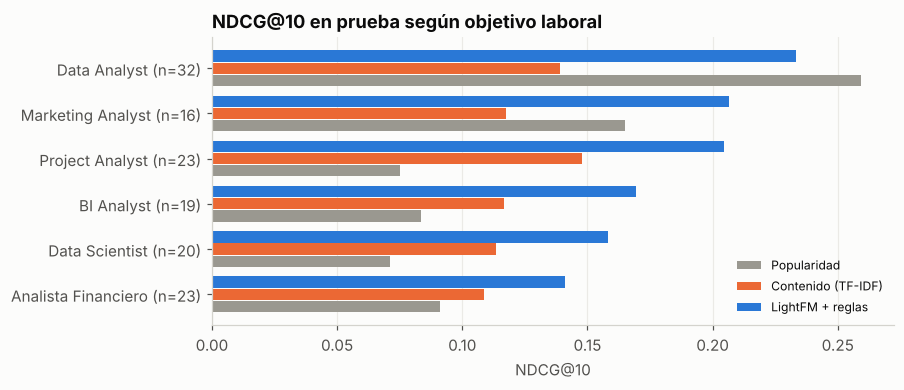

In [ ]:
d10 = {n: det[n].query("K == 10").set_index("user_id") for n in ["Popularidad", "Contenido (TF-IDF)", "KNN usuario", "LightFM + reglas"]}
info = usuarios.set_index("user_id").loc[eleg].copy()
n_hist = prueba.train[prueba.train.positivo == 1].groupby("user_id").size()
info["historial"] = pd.cut(n_hist.reindex(info.index), [0, 4, 8, 100], labels=["corto (≤4)", "medio (5-8)", "largo (>8)"])
seg = []
for col in ["objetivo_laboral", "idioma_preferido", "historial"]:
    for val_, g in info.groupby(col, observed=True):
        fila = {"segmento": col, "valor": val_, "estudiantes": len(g)}
        for n, d in d10.items(): fila[n] = d.loc[g.index, "ndcg"].mean()
        seg.append(fila)
seg = pd.DataFrame(seg).set_index(["segmento", "valor"])
display(seg.round(3))

s_obj = seg.loc["objetivo_laboral"].sort_values("LightFM + reglas")
fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(s_obj)); h = 0.27
for j, (n, c) in enumerate([("Popularidad", GRIS), ("Contenido (TF-IDF)", NARANJA), ("LightFM + reglas", AZUL)]):
    ax.barh(y + (j - 1) * h, s_obj[n], height=h - 0.02, color=c, label=n)
ax.set_yticks(y, [f"{i} (n={s_obj.loc[i, 'estudiantes']})" for i in s_obj.index])
ax.set_title("NDCG@10 en prueba según objetivo laboral"); ax.set_xlabel("NDCG@10"); ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.grid(axis="y", visible=False)
guardar(fig, "18_segmentos_objetivo"); plt.show()

**Interpretación.**
- **Por objetivo laboral:** LightFM + reglas supera a la popularidad en cinco de los seis objetivos. La excepción es **Data Analyst** (0.233 frente a 0.259): para este perfil, los cursos más populares (Excel, SQL, BI) son justamente los que necesita, así que la popularidad ya es una buena recomendación. Donde más aporta la personalización es en los perfiles menos comunes: **Project Analyst** (0.205 frente a 0.075) y **Data Scientist** (0.158 frente a 0.071), que la popularidad prácticamente ignora.
- **Por idioma:** LightFM + reglas mejora a ambos grupos. Los estudiantes que solo leen español obtienen mejores resultados en todos los modelos, porque su espacio de cursos relevantes es más pequeño.
- **Por historial:** LightFM aporta más a los estudiantes con **historial corto** (0.216 frente a 0.116 de la popularidad), gracias a los atributos. Con historial largo (más de 8 inscripciones; solo 18 estudiantes) todos los modelos se parecen: el estudiante ya tomó los cursos más evidentes de su perfil.

## 7. Evaluación del *cold start*

Se simula que los 133 estudiantes de prueba son **nuevos**: se ignora todo su historial y se les recomienda solo con su formulario de registro. Se mide si aciertan sus inscripciones del periodo de prueba. Para comparar, se incluye el modelo completo (que sí usa historial).

In [ ]:
class SoloPerfil:
    def __init__(self, fn): self.fn = fn
    def puntajes(self, u): return self.fn(perfil_de[u])

lf = modelos["LightFM híbrido"]; ct = modelos["Contenido (TF-IDF)"]; pop_s = modelos["Popularidad"].puntajes(None)
cs = {
    "Popularidad filtrada (respaldo)": SoloPerfil(lambda p: rr.aplicar_reglas(pop_s, cursos, p)),
    "Contenido por perfil declarado": SoloPerfil(ct.puntajes_perfil),
    "LightFM solo atributos + reglas (adoptado)": SoloPerfil(lambda p: rr.aplicar_reglas(lf.puntajes_perfil(p), cursos, p)),
}
res_cs = {n: rr.evaluar(m, prueba) for n, m in cs.items()}
res_cs["Referencia: LightFM + reglas con historial"] = res["LightFM + reglas"].loc[[5, 10]]
pd.concat({K: rr.tabla_metricas(res_cs, K)[["precision", "recall", "hit_rate", "ndcg", "cobertura"]] for K in (5, 10)},
          names=["K", "estrategia"]).round(3)

precision  recall  hit_rate  \
K  estrategia                                                                
5  Popularidad filtrada (respaldo)                 0.047   0.159     0.218   
   Contenido por perfil declarado                  0.041   0.142     0.203   
   LightFM solo atributos + reglas (adoptado)      0.063   0.233     0.293   
   Referencia: LightFM + reglas con historial      0.060   0.222     0.293   
10 Popularidad filtrada (respaldo)                 0.039   0.263     0.346   
   Contenido por perfil declarado                  0.034   0.240     0.331   
   LightFM solo atributos + reglas (adoptado)      0.049   0.353     0.429   
   Referencia: LightFM + reglas con historial      0.050   0.357     0.451   

                                                ndcg  cobertura  
K  estrategia                                                    
5  Popularidad filtrada (respaldo)             0.095      0.112  
   Contenido por perfil declarado              0.089      0.607  
   LightFM solo atributos + reglas (adoptado)  0.146      0.626  
   Referencia: LightFM + reglas con historial  0.139      0.654  
10 Popularidad filtrada (respaldo)             0.132      0.196  
   Contenido por perfil declarado              0.124      0.841  
   LightFM solo atributos + reglas (adoptado)  0.189      0.766  
   Referencia: LightFM + reglas con historial  0.189      0.804

**Interpretación.** Sin usar ningún historial, la estrategia adoptada (**LightFM solo con atributos + reglas**) obtiene un NDCG@10 de 0.189 y un Hit Rate@10 de 0.43. Es lo mismo que el modelo con historial (0.189 con la misma semilla) y bastante más que la popularidad filtrada (0.132) o el contenido por perfil declarado (0.124). Un estudiante nuevo recibe recomendaciones casi tan buenas como uno con historial desde el momento en que llena el formulario.

Como ya se advirtió, esto también refleja que en los datos simulados el perfil explica la mayor parte de las elecciones. Con estudiantes reales se espera que el historial pese más. La popularidad filtrada queda como respaldo si el modelo no estuviera disponible.

## 8. Costo computacional

In [ ]:
costo = pd.DataFrame({
    "entrenamiento (s)": {n: tiempos[n] for n in nombres},
    "inferencia por estudiante (ms)": {n: tiempos[n + " · inferencia"] for n in nombres},
})
costo["atiende cold start"] = ["sí (no personaliza)", "sí (perfil declarado)", "no", "no", "sí (atributos)", "sí (atributos + reglas)"]
costo["explicabilidad"] = ["alta", "alta (palabras en común)", "media (estudiantes similares)", "media (cursos similares)", "baja (embeddings)", "baja + reglas explícitas"]
costo.round(3)

,entrenamiento (s),inferencia por estudiante (ms),atiende cold start,explicabilidad
Popularidad,0.008,1.783,sí (no personaliza),alta
Contenido (TF-IDF),0.036,1.712,sí (perfil declarado),alta (palabras en común)
KNN usuario,0.007,1.827,no,media (estudiantes similares)
KNN ítem,0.003,1.956,no,media (cursos similares)
LightFM híbrido,1.377,1.791,sí (atributos),baja (embeddings)
LightFM + reglas,1.377,2.330,sí (atributos + reglas),baja + reglas explícitas


## 9. Selección del modelo

In [ ]:
crit = pd.DataFrame({
    "NDCG@10": tabla_test.loc[10, "ndcg"].reindex(nombres),
    "HR@10": tabla_test.loc[10, "hit_rate"].reindex(nombres),
    "significativo vs. popularidad": sig["¿significativo al 5 %?"].reindex(nombres).fillna("—"),
    "ranking con corte global": rob["ranking (global)"].reindex(nombres),
    "cobertura": mas_alla["cobertura"].reindex(nombres),
    "% inglés a 'solo español'": mas_alla["% en inglés para 'solo español'"].reindex(nombres),
    "entrenamiento (s)": costo["entrenamiento (s)"],
    "cold start": costo["atiende cold start"],
})
crit.round(3)

,NDCG@10,HR@10,significativo vs. popularidad,ranking con corte global,cobertura,% inglés a 'solo español',entrenamiento (s),cold start
Popularidad,0.134,0.346,—,3,0.159,12.500,0.008,sí (no personaliza)
Contenido (TF-IDF),0.126,0.346,no,5,0.879,50.417,0.036,sí (perfil declarado)
KNN usuario,0.129,0.316,no,4,0.729,18.333,0.007,no
KNN ítem,0.130,0.286,no,6,1.000,27.917,0.003,no
LightFM híbrido,0.199,0.462,sí,2,0.794,6.250,1.377,sí (atributos)
LightFM + reglas,0.195,0.438,sí,1,0.804,0.000,1.377,sí (atributos + reglas)


**Modelo seleccionado: LightFM híbrido + reglas de idioma y nivel, con K = 10.**

**Por qué:**
1. **Desempeño:** junto con LightFM puro, es el único que supera a la popularidad de forma estadísticamente significativa (NDCG@10 = 0.195 frente a 0.134; Hit Rate@10 = 0.44 frente a 0.35). La diferencia frente a LightFM puro (0.199) está dentro de la variación entre semillas.
2. **Robustez:** es el primero del ranking con el corte temporal global, donde no existe fuga entre usuarios.
3. **Utilidad para el negocio:** es el único que nunca recomienda cursos en inglés a quien solo lee español ni cursos dos niveles por encima. Un error de ese tipo haría que el estudiante pierda confianza en RutaPro desde la primera visita. Mantiene una cobertura del 80 % del catálogo y unas 4.7 categorías por lista.
4. **Cold start:** atiende a estudiantes nuevos solo con el formulario de registro, con un desempeño similar al de estudiantes con historial.
5. **Costo:** entrena en alrededor de 1 segundo y responde en menos de 2 ms por estudiante. En la app no requiere LightFM, porque los puntajes se calculan con los embeddings exportados.

**Lo que se sacrifica:** explicabilidad. Los embeddings no se interpretan directamente, así que la app explicará cada recomendación con los atributos del curso que coinciden con el perfil del estudiante (categoría, nivel, idioma).

**Por qué no los demás:**
- **Popularidad:** no personaliza y falla con los perfiles menos comunes.
- **Contenido:** no mejora a la popularidad en prueba y recomienda cursos en inglés a la mitad de los estudiantes que solo leen español.
- **KNN:** no supera a la popularidad por la dispersión de la matriz y no atiende a estudiantes nuevos.

## 10. Exportación del modelo final para la aplicación

El modelo seleccionado se **reentrena con todos los datos** (entrenamiento + validación + prueba), como se haría antes de ponerlo en producción, y se exportan:
- los embeddings y sesgos de LightFM, para calcular puntajes con numpy en la app sin instalar LightFM;
- la popularidad global, como respaldo;
- los cursos ya inscritos por cada estudiante, para no volver a recomendarlos.

In [ ]:
todo = rr.Particion(cursos, usuarios, pares.copy(), pares[pares.positivo == 1].copy())
final = rr.LightFMHibrido(**H["LightFM híbrido"], seed=42).fit(todo)
exp = final.exportar()
pop_final = rr.Popularidad().fit(todo).puntajes(None)
APP = BASE / "03_App" / "modelo"; APP.mkdir(parents=True, exist_ok=True)
np.savez_compressed(APP / "lightfm_final.npz", **exp, popularidad=pop_final,
                    course_ids=cursos.course_id.values, user_ids=usuarios.user_id.values)
# Copias del catálogo y de los perfiles para que la carpeta 03_App funcione de forma independiente
cursos.to_csv(APP / "cursos.csv", index=False); usuarios.to_csv(APP / "usuarios.csv", index=False)
inscritos = pares[pares.positivo == 1].groupby("user_id")["course_id"].apply(list).to_dict()
(APP / "inscritos.json").write_text(json.dumps(inscritos, ensure_ascii=False))
(APP / "config.json").write_text(json.dumps({
    "modelo": "LightFM híbrido + reglas de idioma y nivel", "hiperparametros": H["LightFM híbrido"],
    "K_mostrado": 10, "margen_nivel": 1, "entrenado_con": "todos los pares (train + valid + test)",
    "metricas_prueba_K10": tabla_test.loc[(10, "LightFM + reglas")].round(4).to_dict()}, indent=2, ensure_ascii=False))

# Verificación: los puntajes con numpy coinciden con los de LightFM
u0 = usuarios.user_id.iloc[0]
s_np = exp["user_emb"][0] @ exp["item_emb"].T + exp["item_bias"] + exp["user_bias"][0]
print("Máxima diferencia numpy vs LightFM:", float(np.abs(s_np - final.puntajes(u0)).max()))
perf = usuarios.iloc[5].to_dict()
f = final.vector_usuario_nuevo(perf)
s_new = (f @ exp["feat_emb"]) @ exp["item_emb"].T + exp["item_bias"] + f @ exp["feat_bias"]
print("Cold start numpy vs LightFM:", float(np.abs(s_new - final.puntajes_perfil(perf)).max()))
print("Archivos:", sorted(p.name for p in APP.iterdir()))

Máxima diferencia numpy vs LightFM: 1.1444091796875e-05
Cold start numpy vs LightFM: 3.552713678800501e-15
Archivos: ['config.json', 'cursos.csv', 'inscritos.json', 'lightfm_final.npz', 'usuarios.csv']


## 11. Conclusiones de la evaluación

1. **Modelo final: LightFM + reglas.** Con el protocolo temporal por usuario, obtiene en prueba un NDCG@10 de 0.195 y un Hit Rate@10 de 0.44, frente a 0.134 y 0.35 de la popularidad. La mejora es significativa (Wilcoxon con Holm, p = 0.026) y se mantiene con el corte temporal global.
2. **Contenido TF-IDF y KNN** no se distinguen estadísticamente de la popularidad. La dispersión de la matriz limita a KNN, y el contenido no generaliza su pequeña ventaja de validación.
3. **K = 10** equilibra acierto (casi la mitad de los estudiantes encuentra un curso que luego toma) y esfuerzo de revisión.
4. **Más allá de la precisión:** las reglas de negocio eliminan las recomendaciones en un idioma que el estudiante no lee y los saltos de dos niveles, sin pérdida significativa de desempeño.
5. **Cold start:** se atiende con LightFM a partir de los atributos del formulario, con un desempeño similar al de estudiantes con historial.
6. **Limitaciones:**
   - Los datos de interacción son **simulados**, y la regla de simulación depende del perfil del estudiante. Esto favorece a los modelos con atributos, así que las métricas no deben leerse como el desempeño esperado con estudiantes reales.
   - Con 133 estudiantes, los intervalos de confianza son amplios.
   - La partición por usuario admite una fuga entre usuarios, que se controló con la prueba de robustez.
   - Las reglas de idioma pueden ocultar buenos cursos en inglés con subtítulos.
7. **Qué medir después del despliegue:**
   - tasa de clics e inscripción sobre las recomendaciones (prueba A/B contra la popularidad);
   - tasa de finalización de los cursos recomendados;
   - cobertura y diversidad del catálogo recomendado;
   - calificación posterior de los estudiantes;
   - avance hacia el objetivo laboral (por ejemplo, conseguir prácticas).